# 1.2 EDA: electricity vs gas, solar PV, heating fuel, weekends, temperature and sunshine

**Question.** How does household energy use relate to other variables: electricity vs gas across household groups, solar PV, heating fuel, weekday vs weekend, outdoor temperature and solar irradiance?

**Data.** SERL Study 8963 daily-statistics file (yearly and monthly rows) and half-hourly files, read with `serl_energy.dataset`.

**Method.** One group of households in one unit per statistic. **Solar PV:** SERL's PV export and net statistics rest on about 700 homes in 2021 but only 20–60 in 2022–2023, so PV exports and net use are shown for **2021**, and monthly points with fewer than 50 PV homes are marked.

**Outputs.** Figures in `reports/figures/1.2-eda-bivariate/`, tables in `reports/tables/1.2-eda-bivariate/`.


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from serl_energy import dataset as serl, plots
from serl_energy.labels import household_groups, level_label, role
from serl_energy.plots import COLORS, INK, ROLE_COLORS, YEAR_COLORS
from serl_energy.reporting import Reporter

warnings.filterwarnings("ignore", category=UserWarning)
plots.use_theme()
reporter = Reporter("1.2-eda-bivariate")

yearly = serl.load_yearly()
monthly = serl.load_monthly(serl.CLEAN_CSV)
hh = serl.load_half_hourly([2021, 2023])
y23 = yearly[yearly["year"].eq(2023)]
MIN_HOUSEHOLDS = 50

def kwh_day(df, q, **f):
    return serl.select_slice(df, q, "kWh/day", **f)["mean"].iloc[0]

## 1. Electricity vs gas across household groups (2023)

Each point is one SERL household group (PV, heating fuel, and every level of every characteristic except temperature band). Groups linked to energy poverty are red, their comparators violet. **Look for:** groups that use more gas also use more electricity, because both scale with home and household size; electric-heated homes sit apart (low gas, high electricity).


72 groups; Spearman correlation electricity vs gas = 0.66 (p = 3.12e-10)


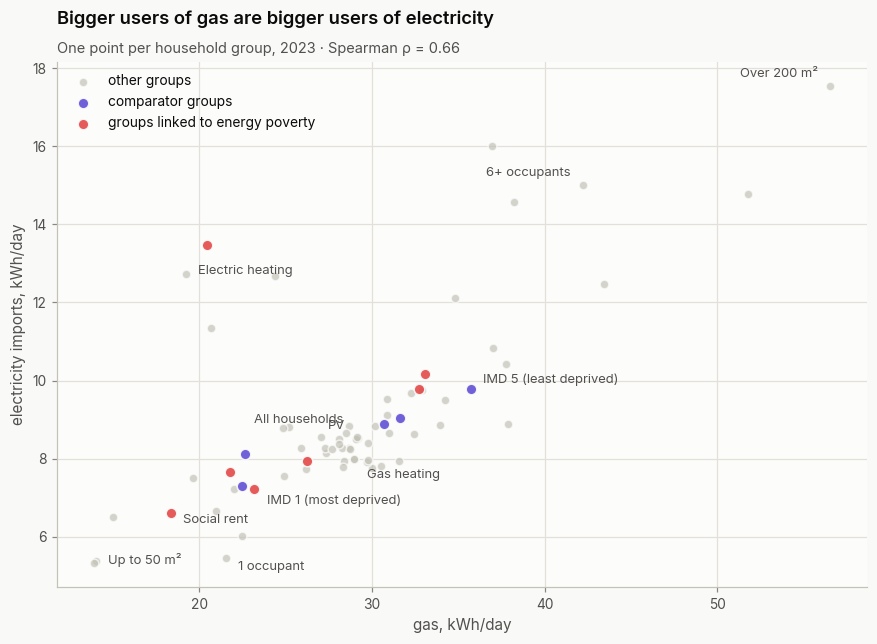

In [2]:
rows = []
for label, f in household_groups(y23):
    try:
        rows.append({"group_label": label, "segment": f.get("segment", ""), "segment_value": f.get("segment_value", ""),
                     "role": role(f["segment"], f["segment_value"]) if "segment" in f else "other",
                     "electricity_kwh_per_day": kwh_day(y23, "Electricity imports", **f),
                     "gas_kwh_per_day": kwh_day(y23, "Gas", **f)})
    except ValueError:
        pass                      # group not reported for this quantity
eg = pd.DataFrame(rows).dropna(subset=["electricity_kwh_per_day", "gas_kwh_per_day"])
rho, p = spearmanr(eg["electricity_kwh_per_day"], eg["gas_kwh_per_day"])
print(f"{len(eg)} groups; Spearman correlation electricity vs gas = {rho:.2f} (p = {p:.3g})")
reporter.save_table(eg, "electricity_vs_gas_by_group_2023")

fig, ax = plt.subplots(figsize=(9.5, 6.2))
for r in ("other", "comparator", "vulnerable"):
    d = eg[eg["role"].eq(r)]
    ax.scatter(d["gas_kwh_per_day"], d["electricity_kwh_per_day"], s=48 if r != "other" else 32,
               color=ROLE_COLORS[r], alpha=0.9 if r != "other" else 0.7, edgecolor=COLORS["surface"], linewidth=1,
               label={"other": "other groups", "comparator": "comparator groups",
                      "vulnerable": "groups linked to energy poverty"}[r], zorder=3)
# labels placed by hand so they never overlap
LABELS = {"All households": (-8, 10), "Electric heating": (8, 0), "Gas heating": (8, -12), "PV": (-8, 6),
          "Over 200 m²": (-8, 6), "Up to 50 m²": (8, -2), "1 occupant": (8, -8), "6+ occupants": (-8, 6),
          "IMD 1 (most deprived)": (8, -10), "IMD 5 (least deprived)": (8, 4), "Social rent": (8, -6)}
for _, r in eg[eg["group_label"].isin(LABELS)].iterrows():
    dx, dy = LABELS[r["group_label"]]
    ax.annotate(r["group_label"], (r["gas_kwh_per_day"], r["electricity_kwh_per_day"]), xytext=(dx, dy),
                textcoords="offset points", fontsize=8.5, color=INK["secondary"], ha="left" if dx > 0 else "right")
ax.set_xlabel("gas, kWh/day"); ax.set_ylabel("electricity imports, kWh/day")
ax.legend(loc="upper left")
plots.title(ax, "Bigger users of gas are bigger users of electricity",
            f"One point per household group, 2023 · Spearman ρ = {rho:.2f}")
reporter.save_fig(fig, "electricity-vs-gas-by-group")
plt.show()

## 2. Homes with and without solar PV (2021)

PV homes' half-hourly imports (above zero) and exports (below zero, mirrored), with their net use, against homes without PV. 2021 is the last year with enough PV homes in SERL's export statistics. **Look for:** midday exports almost cancel daytime imports, but the evening peak is as large as in homes without PV.


           quantity  pv  kwh_per_day  households
Electricity imports Yes        10.05         720
Electricity exports Yes         4.59         700
    Electricity net Yes         5.42         680
Electricity imports  No        10.09       10080


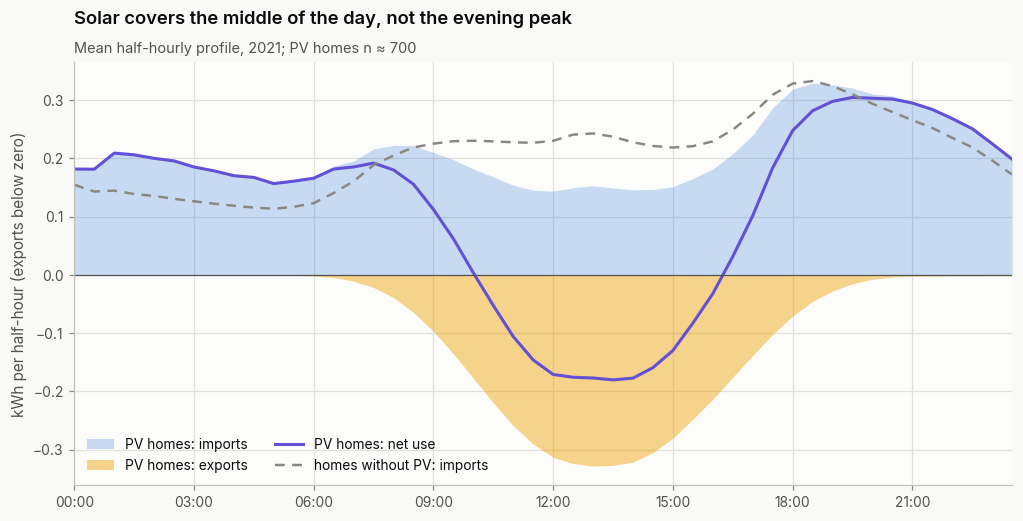

In [3]:
YEAR_PV = 2021
prof = {q: serl.daily_profile(hh, YEAR_PV, q, "Wh", to_kwh=True, pv="Yes")
        for q in ("Electricity imports", "Electricity exports", "Electricity net")}
no_pv = serl.daily_profile(hh, YEAR_PV, "Electricity imports", "Wh", to_kwh=True, pv="No")
n = {q: int(serl.select_slice(hh[hh["year"].eq(YEAR_PV)], q, "Wh", pv="Yes")["n_rounded"].min()) for q in prof}
pv_table = pd.DataFrame({"quantity": list(prof) + ["Electricity imports"], "pv": ["Yes"] * 3 + ["No"],
                         "kwh_per_day": [p.sum() for p in prof.values()] + [no_pv.sum()],
                         "households": list(n.values()) + [int(serl.select_slice(hh[hh["year"].eq(YEAR_PV)],
                                                                "Electricity imports", "Wh", pv="No")["n_rounded"].min())]})
print(pv_table.round(2).to_string(index=False))
reporter.save_table(pv_table, "pv_profiles_2021")

x = np.arange(48)
fig, ax = plt.subplots(figsize=(11, 5))
ax.fill_between(x, 0, prof["Electricity imports"], color=COLORS["electricity"], alpha=0.25, lw=0, label="PV homes: imports")
ax.fill_between(x, 0, -prof["Electricity exports"], color=COLORS["solar_export"], alpha=0.45, lw=0,
                label="PV homes: exports")
ax.plot(x, prof["Electricity net"], color=COLORS["net_electricity"], label="PV homes: net use")
ax.plot(x, no_pv, color=INK["muted"], ls=(0, (4, 3)), lw=1.6, label="homes without PV: imports")
ax.axhline(0, color=INK["secondary"], lw=0.8)
plots.half_hour_axis(ax); ax.set_ylabel("kWh per half-hour (exports below zero)")
ax.legend(loc="lower left", ncols=2)
plots.title(ax, "Solar covers the middle of the day, not the evening peak",
            f"Mean half-hourly profile, {YEAR_PV}; PV homes n ≈ {n['Electricity exports']}")
reporter.save_fig(fig, "pv-import-export-profile-2021")
plt.show()

## 3. Gas-heated vs electric-heated homes

Electricity imports through the day (2023) and through the year (monthly, 2020–2023). **Look for:** electric-heated homes use more electricity at every hour, and far more in winter.


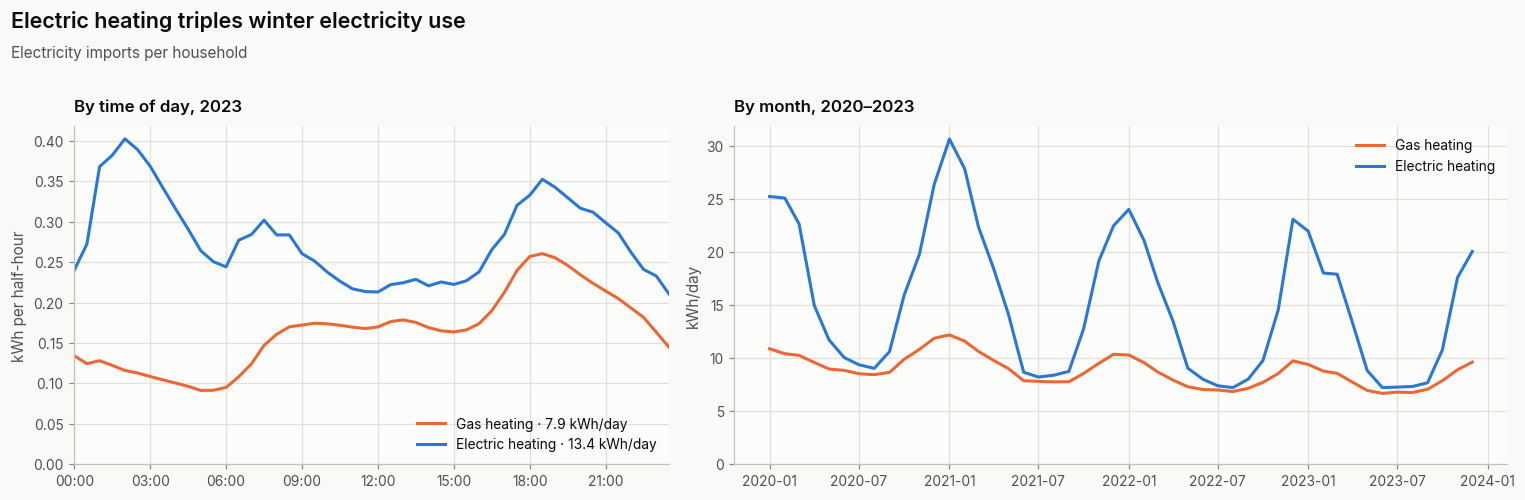

In [4]:
fuels = {"Gas": COLORS["gas_heating"], "Electric": COLORS["electric_heating"]}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.3]})
rows = []
for fuel, color in fuels.items():
    p = serl.daily_profile(hh, 2023, "Electricity imports", "Wh", to_kwh=True, fuel=fuel)
    axes[0].plot(range(48), p.to_numpy(), color=color, label=f"{fuel} heating · {p.sum():.1f} kWh/day")
    s = serl.monthly_series(monthly, "Electricity imports", "kWh/day", fuel=fuel)
    axes[1].plot(s.index, s.to_numpy(), color=color, label=f"{fuel} heating")
    rows += [{"heating_fuel": fuel, "month": d.strftime("%Y-%m"), "electricity_kwh_per_day": v} for d, v in s.items()]
plots.half_hour_axis(axes[0]); axes[0].set_ylabel("kWh per half-hour"); axes[0].set_ylim(bottom=0)
axes[0].set_title("By time of day, 2023", loc="left", fontsize=11); axes[0].legend(loc="lower right")
axes[1].set_ylabel("kWh/day"); axes[1].set_ylim(bottom=0); axes[1].legend(loc="upper right")
axes[1].set_title("By month, 2020–2023", loc="left", fontsize=11)
plots.figure_title(fig, "Electric heating triples winter electricity use", "Electricity imports per household")
reporter.save_fig(fig, "electricity-by-heating-fuel")
plt.show()
reporter.save_table(pd.DataFrame(rows), "electricity_by_heating_fuel_monthly")

## 4. Weekdays vs weekends

SERL splits weekdays and weekends for the whole sample only. Left: each year's weekday and weekend mean (dumbbell). Right: weekend minus weekday through the day (2023), above zero = more at weekends. **Look for:** weekends use about 5% more electricity, spread across late morning and midday; the gas morning peak starts later.


                          weekday  weekend  weekend_to_weekday
quantity            year                                      
Electricity imports 2020   10.799   11.435               1.059
                    2021    9.965   10.472               1.051
                    2022    8.670    9.043               1.043
                    2023    8.401    8.790               1.046
Gas                 2020   37.034   36.287               0.980
                    2021   38.103   40.128               1.053
                    2022   30.332   30.688               1.012
                    2023   28.980   29.274               1.010


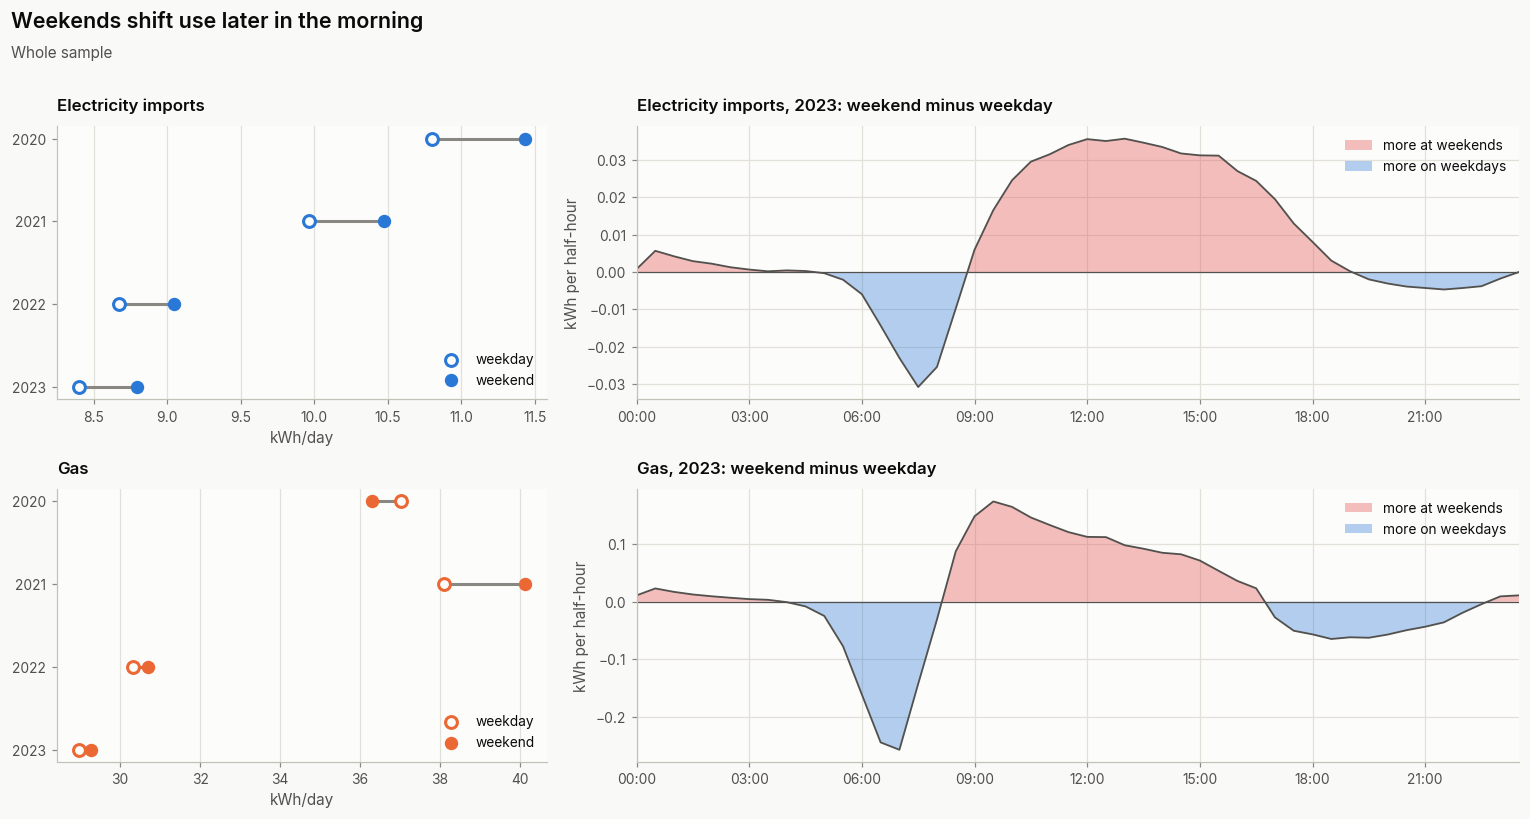

In [5]:
rows = []
for q in ["Electricity imports", "Gas"]:
    for day in ("weekday", "weekend"):
        s = serl.select_slice(yearly, q, "kWh/day", weekday_weekend=day).set_index("year")["mean"]
        rows += [{"quantity": q, "day_type": day, "year": y, "kwh_per_day": v} for y, v in s.items()]
days = pd.DataFrame(rows).pivot_table(index=["quantity", "year"], columns="day_type", values="kwh_per_day")
days.columns.name = None
days["weekend_to_weekday"] = days["weekend"] / days["weekday"]
print(days.round(3).to_string())
reporter.save_table(days.reset_index(), "weekday_weekend_by_year")

fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), gridspec_kw={"width_ratios": [1, 1.8]})
for row, (q, color) in zip(axes, {"Electricity imports": COLORS["electricity"], "Gas": COLORS["gas"]}.items()):
    ax = row[0]
    d = days.loc[q]
    ax.hlines(d.index, d["weekday"], d["weekend"], color=INK["muted"], lw=2)
    ax.scatter(d["weekday"], d.index, color=COLORS["surface"], edgecolor=color, linewidth=2, s=60, zorder=3,
               label="weekday")
    ax.scatter(d["weekend"], d.index, color=color, s=60, zorder=3, label="weekend")
    ax.set_yticks(d.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.set_xlabel("kWh/day")
    ax.set_title(q, loc="left", fontsize=11); ax.legend(loc="lower right")
    ax = row[1]
    diff = (serl.daily_profile(hh, 2023, q, "Wh", to_kwh=True, weekday_weekend="weekend")
            - serl.daily_profile(hh, 2023, q, "Wh", to_kwh=True, weekday_weekend="weekday")).to_numpy()
    ax.fill_between(range(48), 0, diff, where=diff >= 0, color=COLORS["vulnerable"], alpha=0.35, lw=0,
                    interpolate=True, label="more at weekends")
    ax.fill_between(range(48), 0, diff, where=diff < 0, color=COLORS["electricity"], alpha=0.35, lw=0,
                    interpolate=True, label="more on weekdays")
    ax.plot(range(48), diff, color=INK["secondary"], lw=1.2)
    ax.axhline(0, color=INK["secondary"], lw=0.8)
    plots.half_hour_axis(ax); ax.set_ylabel("kWh per half-hour")
    ax.set_title(f"{q}, 2023: weekend minus weekday", loc="left", fontsize=11); ax.legend(loc="upper right")
plots.figure_title(fig, "Weekends shift use later in the morning", "Whole sample")
reporter.save_fig(fig, "weekday-vs-weekend")
plt.show()

## 5. Use vs outdoor temperature

SERL's *temperature band* rows give each household's average use on days whose mean outdoor temperature falls in a band (2023): a direct temperature-response curve, without a regression. **Look for:** gas rises steeply below 15 °C; electricity rises steeply only in electric-heated homes.


temperature_band                  -5_to_0  0_to_5  5_to_10  10_to_15  15_to_20  20_to_25
quantity            heating_fuel                                                        
Electricity imports All             11.53   10.61     9.50      7.98      7.03      7.02
                    Gas             10.00    9.36     8.68      7.56      6.86      6.88
                    Electric        26.73   22.67    17.02     11.07      7.41      7.02
Gas                 All             78.75   63.03    43.66     20.10      6.95      5.66
                    Gas             78.78   62.98    43.53     19.96      6.90      5.63
                    Electric        45.14   38.23    27.18     14.76      5.60      4.97


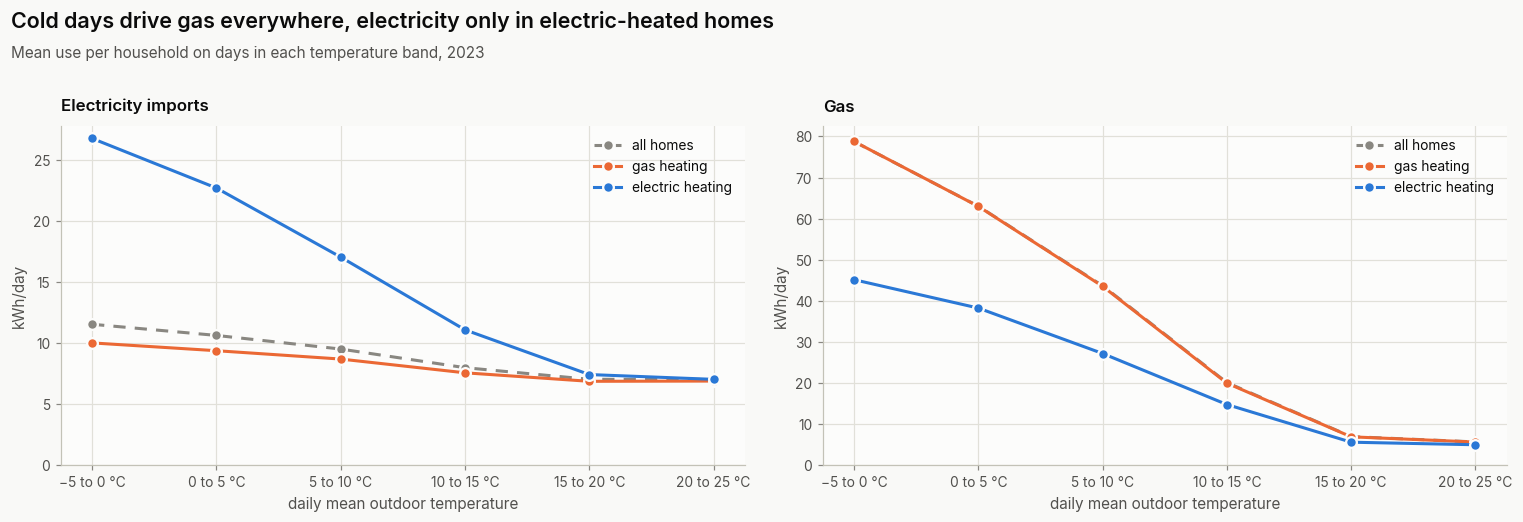

In [6]:
BANDS = ["-5_to_0", "0_to_5", "5_to_10", "10_to_15", "15_to_20", "20_to_25"]
rows = []
for q in ["Electricity imports", "Gas"]:
    for fuel in ("All", "Gas", "Electric"):
        s = serl.select_slice(y23, q, "kWh/day", fuel=fuel, segment="temperature_band").set_index("segment_3_value")
        s = s.reindex(BANDS)
        rows += [{"quantity": q, "heating_fuel": fuel, "temperature_band": b, "kwh_per_day": v, "households": n}
                 for b, v, n in zip(BANDS, s["mean"], s["n_rounded"])]
temp = pd.DataFrame(rows)
print(temp.pivot_table(index=["quantity", "heating_fuel"], columns="temperature_band", values="kwh_per_day",
                       sort=False).round(2).to_string())
reporter.save_table(temp, "temperature_response_2023")

style = {"All": (INK["muted"], "all homes", (0, (4, 3))), "Gas": (COLORS["gas_heating"], "gas heating", "-"),
         "Electric": (COLORS["electric_heating"], "electric heating", "-")}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, q in zip(axes, ["Electricity imports", "Gas"]):
    for fuel, (color, label, ls) in style.items():
        t = temp[temp["quantity"].eq(q) & temp["heating_fuel"].eq(fuel)]
        ax.plot(range(len(BANDS)), t["kwh_per_day"], color=color, ls=ls, marker="o", markersize=7,
                markeredgecolor=COLORS["surface"], markeredgewidth=1.5, label=label)
    ax.set_xticks(range(len(BANDS)), [level_label("temperature_band", b) for b in BANDS])
    ax.set_xlabel("daily mean outdoor temperature"); ax.set_ylabel("kWh/day"); ax.set_ylim(bottom=0)
    ax.set_title(q, loc="left", fontsize=11); ax.legend(loc="upper right")
plots.figure_title(fig, "Cold days drive gas everywhere, electricity only in electric-heated homes",
                   "Mean use per household on days in each temperature band, 2023")
reporter.save_fig(fig, "temperature-response-2023")
plt.show()

## 6. Solar irradiance and PV homes

Monthly mean exports and imports of PV homes against monthly mean solar irradiance (2020–2023), coloured by year. Monthly PV counts hold up better than the yearly export rows; hollow points mark the months with fewer than 50 PV homes behind them, which are excluded from the correlations.


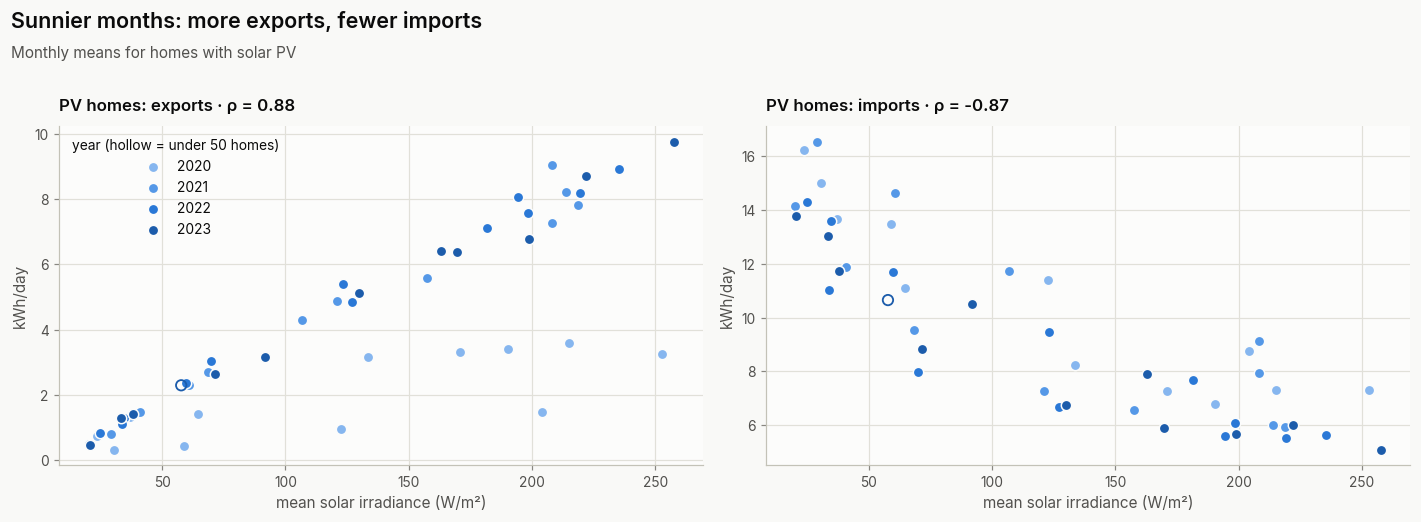

           quantity  months_used  months_excluded  spearman_rho_solar
electricity_exports           47                1                0.88
electricity_imports           47                1               -0.87


In [7]:
pv = serl.select_slice(monthly, "Electricity exports", "kWh/day", pv="Yes")
imp = serl.select_slice(monthly, "Electricity imports", "kWh/day", pv="Yes")
rows = []
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, s, name in ((axes[0], pv, "exports"), (axes[1], imp, "imports")):
    ok = s["n_rounded"].ge(MIN_HOUSEHOLDS)
    rho_ok, _ = spearmanr(s.loc[ok, "mean_solar"], s.loc[ok, "mean"])
    rows.append({"quantity": f"electricity_{name}", "months_used": int(ok.sum()), "months_excluded": int((~ok).sum()),
                 "spearman_rho_solar": rho_ok})
    for y in serl.YEARS:
        d = s[s["date"].dt.year.eq(y)]
        good, bad = d[d["n_rounded"].ge(MIN_HOUSEHOLDS)], d[d["n_rounded"].lt(MIN_HOUSEHOLDS)]
        ax.scatter(good["mean_solar"], good["mean"], color=YEAR_COLORS[y], s=46, edgecolor=COLORS["surface"],
                   linewidth=1, label=str(y), zorder=3)
        ax.scatter(bad["mean_solar"], bad["mean"], facecolor="none", edgecolor=YEAR_COLORS[y], s=46, linewidth=1.2,
                   zorder=3)
    ax.set_xlabel("mean solar irradiance (W/m²)"); ax.set_ylabel("kWh/day")
    ax.set_title(f"PV homes: {name} · ρ = {rho_ok:.2f}", loc="left", fontsize=11)
axes[0].legend(title="year (hollow = under 50 homes)", loc="upper left")
plots.figure_title(fig, "Sunnier months: more exports, fewer imports", "Monthly means for homes with solar PV")
reporter.save_fig(fig, "pv-vs-solar-irradiance")
plt.show()
solar = pd.DataFrame(rows)
print(solar.round(2).to_string(index=False))
reporter.save_table(solar, "pv_solar_correlation")

## Conclusions

- **Electricity and gas rise together across household groups** (Spearman ρ ≈ 0.66), because both scale with home and household size; electric-heated homes are the main exception.
- **Solar PV cuts daytime imports but not the evening peak.** In 2021, PV homes exported about 4.6 kWh/day around midday, yet their evening imports were almost the same as in homes without PV, so PV alone does little for peak demand.
- **Electric heating dominates winter electricity:** electric-heated homes use almost four times as much electricity on the coldest days (−5 to 0 °C) as on warm days (26.7 vs 7.0 kWh/day).
- **Weekends use about 5% more electricity**, mostly late morning and midday; gas differs little.
- **Gas use rises steeply below 15 °C**: about 14 times higher on the coldest days than the warmest (78.8 vs 5.7 kWh/day).

## Limitations

- Group-level statistics, one characteristic at a time, so relationships are not adjusted for each other.
- PV statistics after 2021 rest on very few homes; PV results are 2021-based.
- The temperature-band rows pool days across the whole year, so they mix temperature with season (daylight, holidays).
